# LeetCode #64: Minimum Path Sum

https://leetcode.com/problems/minimum-path-sum/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute Force: Try Every Path** | $O(2^{m+n})$ | $O(m+n)$ | Walk every right/down route and keep the cheapest. A 200 × 200 grid has around $10^{119}$ routes. |
| **2D Table** | $O(m \times n)$ | $O(m \times n)$ | One box per square holding the cheapest cost to reach it, each filled once from the box above and the box to its left. At 200 × 200, 40,000 boxes. |
| **One Row, Reused** ★ | $O(m \times n)$ | $O(n)$ | The same rule, but only one row of 200 numbers is kept, overwritten in place as each new row is processed. |

$m$ is the number of rows and $n$ the number of columns. $O(m \times n)$ means the work grows with the number of squares: 40,000 steps at the largest grid. $O(2^{m+n})$ means every extra row or column roughly doubles the work. $O(n)$ space means memory grows only with the width.

---

## Understanding the Methods

Each square has a cost. Start in the top-left, finish in the bottom-right, move only **right** or **down**, and find the route whose costs add up to the least. Both end squares count.

### Brute Force: Try Every Path
Recursively try going right and going down from every square and keep the smallest total. The same squares are re-solved along countless routes.

### 2D Table
A route into a square arrives from above or from the left. So the cheapest way to reach it is the cheaper of those two plus its own cost: `best(r, c) = min(best(r-1, c), best(r, c-1)) + grid[r][c]`. The top row can only be reached from the left and the left column only from above, so those are running sums.

### Optimal: One Row, Reused ★
Filling a row only needs the row above and the box just filled to its left. Keep one array `dp`. While walking a row, `dp[j]` still holds the row above's value until it's overwritten, and `dp[j-1]` already holds this row's left neighbour. So `dp[j] = min(dp[j], dp[j-1]) + grid[i][j]`.

**Why this is better than the 2D table:** the same 40,000 steps and the same answer, with 200 numbers in memory instead of 40,000.

**Constraints:**
* `1 <= m, n <= 200`
* `0 <= grid[i][j] <= 200`

## Explain Like I'm a Newbie

### What the question is actually asking

Each square costs something. Walk from the top-left square to the bottom-right one, stepping only right or down, and pay for every square you stand on. What's the least you can pay?

```
1 3 1         cheapest route: 1 → 3 → 1 → 1 → 1 = 7
1 5 1         (right, right, down, down)
4 2 1
```

### The one idea you need: the cheapest way *into* each square

Looking only at the next step doesn't work. From the top-left, going down to the 1 looks cheaper than going right to the 3, but that route then has to pay the 4 or the 5 later and ends up costing 9.

So don't choose a route as you go. Ask, for every square, **what's the cheapest way to reach it?** You can only arrive from above or from the left, so it's the cheaper of those two plus the square's own cost. Fill the grid row by row and the bottom-right square holds the answer. The top row has nothing above it, so it's a running total from the left; the left column likewise from above.

### What that means in code

The code keeps one row, `dp`. It first fills it with the top row's running totals. For each later row, `dp[0] += grid[i][0]` handles the left column (only from above), then for `j = 1` onwards `dp[j] = min(dp[j], dp[j-1]) + grid[i][j]`. At that moment `dp[j]` is still the square above and `dp[j-1]` is the square to the left. This is **dynamic programming**: each answer is built from smaller ones already stored.

### Mistakes people make the first time

1. **Choosing the cheaper neighbour at each step.** That's a guess about the future, and the first sample already catches it: it pays 9 instead of 7.
2. **Running the inner loop from `j = 0` in Python.** Both samples pass. But at `j = 0`, `dp[j-1]` is `dp[-1]`, the *last* column, so the first square of a row can take its cost from the far right, a jump no route can make. `[[1,1,1],[9,9,1],[1,9,9],[1,1,1]]` then gives 8 instead of 14.
3. **Starting every square of the top row at 0 "from above".** `min` then picks the imaginary 0, and the top row loses its running total.

### Things worth knowing

The cheapest *route* isn't stored, only its cost. To recover the route you'd keep the full table and walk back from the corner, choosing whichever neighbour gave the minimum.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"The cheapest way into a square is the cheaper of the square above and the square to its left, plus the square's own cost. The top row and left column have only one way in, so they're running sums. I fill row by row, and since each row only needs the row above, I keep a single array: before I overwrite `dp[j]` it's the value above, and `dp[j-1]` is this row's left. $O(m \times n)$ time, $O(n)$ memory."*

And then, unprompted: *"greedy, taking the cheaper next square, is the tempting wrong answer. The first sample already breaks it."*

---

### I slide the problem across the table

> **You:** "Right and down only, from top-left to bottom-right, and the cost is the sum of every square on the route, both ends included? Can costs be negative?"

**"Both ends count, and costs are between 0 and 200."** The negative question is the one I'm glad to hear. With right and down only it doesn't break the algorithm, since there's no way to loop, but it tells me you're checking what the `min` is allowed to assume.

> **You:** "And the biggest grid is 200 by 200, so the largest possible sum is about 400 squares times 200, which is 80,000. No overflow worries."

**"Right."** That's the kind of sizing I like to hear unprompted, and it's quick.

What I don't need is "should I return the path too?" It says "return the minimum sum". If you want to mention the path as an extension at the end, that's different.

---

### Now tell me what's actually hard about it

If you open with "DP", I'll ask what the state is. I want the difficulty first:

> **You:** "A local choice doesn't work. In the first sample, going down to the 1 looks cheaper than going right to the 3, and that route ends up at 9 instead of 7. What's cheap now can force something expensive later."

> **You:** "But I don't need to know the future if I flip the question: what's the cheapest way to *reach* each square? You only arrive from above or from the left, so that's the cheaper of those two, plus the square itself. Every route through a square uses the cheapest way in, so I never need the others."

That last sentence is the one that makes it a proof rather than a pattern. It's why the table can throw everything else away.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "Rows outside, columns inside, constant work per square: $m \times n$, 40,000 at the limit. A full table is 40,000 numbers, but each row only reads the row above, so one row of 200 is enough."

If you write the 2D table first, I won't mind. I'll ask what you actually read when filling row `i`, and the answer I want is "row `i-1` and the cell to my left, which is why one array does it".

---

### Now whiteboard it

```
m, n = len(grid), len(grid[0])
dp = [0] * n
dp[0] = grid[0][0]
for j in range(1, n):
    dp[j] = dp[j - 1] + grid[0][j]
```

> **You:** "Top row first, as running sums. Nothing above it, so I can't use `min` here: the zeros in `dp` would look like a free route from above."

That's the line where people quietly go wrong, and you've just said why.

```
for i in range(1, m):
    dp[0] += grid[i][0]
    for j in range(1, n):
        dp[j] = min(dp[j], dp[j - 1]) + grid[i][j]
return dp[-1]
```

> **You:** "`dp[0]` gets its own line because the left column can only be reached from above. The inner loop starts at 1 for the same reason. In Python, starting at 0 wouldn't even crash: `dp[-1]` is the last column, and the left edge would quietly borrow from the right edge."

If you don't say why the loop starts at 1, that's my question, because in Python both samples still pass when it starts at 0. A candidate who knows that `dp[-1]` wraps around is one I trust with index arithmetic.

> **You:** "At the `min`, `dp[j]` is still the square above, because I haven't written it yet this row, and `dp[j-1]` is this row's left neighbour, because I just wrote it."

---

### Walk me through it before you say you're done

> **You:** "First sample. Top row running sums: `[1, 4, 5]`. Row 1: `dp[0]` is 1 + 1 = 2. Then min(4, 2) + 5 = 7, then min(5, 7) + 1 = 6. Row 2: `dp[0]` is 2 + 4 = 6. Then min(7, 6) + 2 = 8, then min(6, 8) + 1 = 7. Answer 7."

Then the edges:

> **You:** "A single row never enters the outer loop: it's the running sum. A single column skips the inner loop each time: `dp[0]` just accumulates. And a 1 × 1 grid returns its one value."

That's what I want: the sample, and then the shapes where half the code doesn't run.

---

### Then tell me where it breaks, before I ask

It's optimal: every square has to be looked at. So the honest beats are what it leans on and what it gives up:

> **You:** "It leans on moves being right and down only. That makes the grid a one-way street, so a square's best cost never changes after I've written it. With all four directions, routes can go back and forth, and this becomes a shortest-path problem: Dijkstra, with a priority queue."

> **You:** "And by keeping one row, I've thrown away the route itself. If you want the path, I keep the full table and walk back from the corner, choosing whichever neighbour gave the minimum. That's the space I'd be trading."

That's a candidate who knows exactly which property of the moves makes a single pass enough.

---

### What would worry me

- **Greedy**, taking the cheaper next square, without testing it on the first sample.
- **`min` on the top row**, against zeros that aren't real routes.
- **An inner loop from 0** and no explanation of what `dp[j-1]` is at `j = 0`.
- **A 2D table** with no answer for "do you need all of it?"

## Solutions

### C#

In [ ]:
public class Solution {
    public int MinPathSum(int[][] grid) {
        int m = grid.Length, n = grid[0].Length;
        // One row, reused: dp[j] = cheapest cost to reach column j of the current row
        int[] dp = new int[n];

        // Top row: only reachable from the left, so it's a running sum.
        // (No min here: the zeros in dp would look like a free route from above)
        dp[0] = grid[0][0];
        for (int j = 1; j < n; j++)
            dp[j] = dp[j - 1] + grid[0][j];

        for (int i = 1; i < m; i++) {
            // Left column: only reachable from above
            dp[0] += grid[i][0];

            // Starts at 1: column 0 has no left neighbour
            for (int j = 1; j < n; j++) {
                // dp[j] still holds the square ABOVE (not overwritten yet this row);
                // dp[j-1] is this row's LEFT neighbour. Cheaper way in + own cost
                dp[j] = Math.Min(dp[j], dp[j - 1]) + grid[i][j];
            }
        }

        return dp[n - 1];
    }
}

### Python

`range(1, n)` matters more in Python than elsewhere. Starting at 0, `dp[j - 1]` would be `dp[-1]`, the last element, so instead of an error you'd get a wrong answer that both LeetCode samples happen to accept.

In [ ]:
class Solution:
    def minPathSum(self, grid: list[list[int]]) -> int:
        m, n = len(grid), len(grid[0])
        # One row, reused: dp[j] = cheapest cost to reach column j of the current row
        dp = [0] * n

        # Top row: only reachable from the left, so it's a running sum.
        # (No min here: the zeros in dp would look like a free route from above)
        dp[0] = grid[0][0]
        for j in range(1, n):
            dp[j] = dp[j - 1] + grid[0][j]

        for i in range(1, m):
            # Left column: only reachable from above
            dp[0] += grid[i][0]

            # Starts at 1: column 0 has no left neighbour. (From 0, Python's
            # dp[-1] would silently read the LAST column instead of failing)
            for j in range(1, n):
                # dp[j] still holds the square ABOVE (not overwritten yet this row);
                # dp[j-1] is this row's LEFT neighbour. Cheaper way in + own cost
                dp[j] = min(dp[j], dp[j - 1]) + grid[i][j]

        return dp[-1]

### Go

In [ ]:
func minPathSum(grid [][]int) int {
    m, n := len(grid), len(grid[0])
    // One row, reused: dp[j] = cheapest cost to reach column j of the current row
    dp := make([]int, n)

    // Top row: only reachable from the left, so it's a running sum.
    // (No min here: the zeros in dp would look like a free route from above)
    dp[0] = grid[0][0]
    for j := 1; j < n; j++ {
        dp[j] = dp[j-1] + grid[0][j]
    }

    for i := 1; i < m; i++ {
        // Left column: only reachable from above
        dp[0] += grid[i][0]

        // Starts at 1: column 0 has no left neighbour
        for j := 1; j < n; j++ {
            // dp[j] still holds the square ABOVE (not overwritten yet this row);
            // dp[j-1] is this row's LEFT neighbour. Cheaper way in + own cost
            if dp[j] < dp[j-1] {
                dp[j] = dp[j] + grid[i][j]   // from above
            } else {
                dp[j] = dp[j-1] + grid[i][j] // from the left
            }
        }
    }

    return dp[n-1]
}

### Rust

In [ ]:
impl Solution {
    pub fn min_path_sum(grid: Vec<Vec<i32>>) -> i32 {
        let m = grid.len();
        let n = grid[0].len();
        // One row, reused: dp[j] = cheapest cost to reach column j of the current row
        let mut dp = vec![0i32; n];

        // Top row: only reachable from the left, so it's a running sum.
        // (No min here: the zeros in dp would look like a free route from above)
        dp[0] = grid[0][0];
        for j in 1..n {
            dp[j] = dp[j - 1] + grid[0][j];
        }

        for i in 1..m {
            // Left column: only reachable from above
            dp[0] += grid[i][0];

            // Starts at 1: column 0 has no left neighbour
            for j in 1..n {
                // dp[j] still holds the square ABOVE (not overwritten yet this row);
                // dp[j-1] is this row's LEFT neighbour. Cheaper way in + own cost
                dp[j] = dp[j].min(dp[j - 1]) + grid[i][j];
            }
        }

        dp[n - 1]
    }
}

## Example Scenarios

### 1. Common Case — The 3 × 3 Sample
**Input:** `grid = [[1,3,1],[1,5,1],[4,2,1]]`

The top row's running sums are `[1,4,5]`; row 1 becomes `[2,7,6]` and row 2 `[6,8,7]`. The cheapest route is right, right, down, down: $1 + 3 + 1 + 1 + 1 = 7$. **Output:** `7`

### 2. Slightly Complex — Two Rows
**Input:** `grid = [[1,2,3],[4,5,6]]`

The top row sums to `[1,3,6]`. In row 1 every square is cheaper to reach from above than from the left, giving `[5,8,12]`: along the top, then down at the end, $1 + 2 + 3 + 6 = 12$. **Output:** `12`

### 3. Edge Case: Time Factor — The Largest Grid
**Input:** `grid` is 200 × 200 with every value `100`

All 40,000 squares are processed, each once with one `min`. Every route has $200 + 200 - 1 = 399$ squares, so every route costs $399 \times 100 = 39{,}900$. **Output:** `39900`

### 4. Edge Case: Space Factor — The Widest Row
**Input:** `grid = [[1,2,3,...,100,1,2,3,...,100]]` (one row, 200 values)

The reused row is as wide as the grid allows, 200 numbers, and the outer loop never runs: the answer is the running sum of the row, $2 \times (1 + 2 + \dots + 100) = 10{,}100$. **Output:** `10100`

### 5. Almost-Impossible but Plausible — The Cheap First Step Is a Trap
**Input:** `grid = [[1,1,1,1],[2,9,9,1],[2,9,9,9],[2,2,2,1]]`

Choosing the cheaper next square runs along the cheap top row and is then forced through the 9 at the bottom of the right column: 15. Down the left side and along the bottom costs only 12, and the table finds it because it never commits to a route early. **Output:** `12`

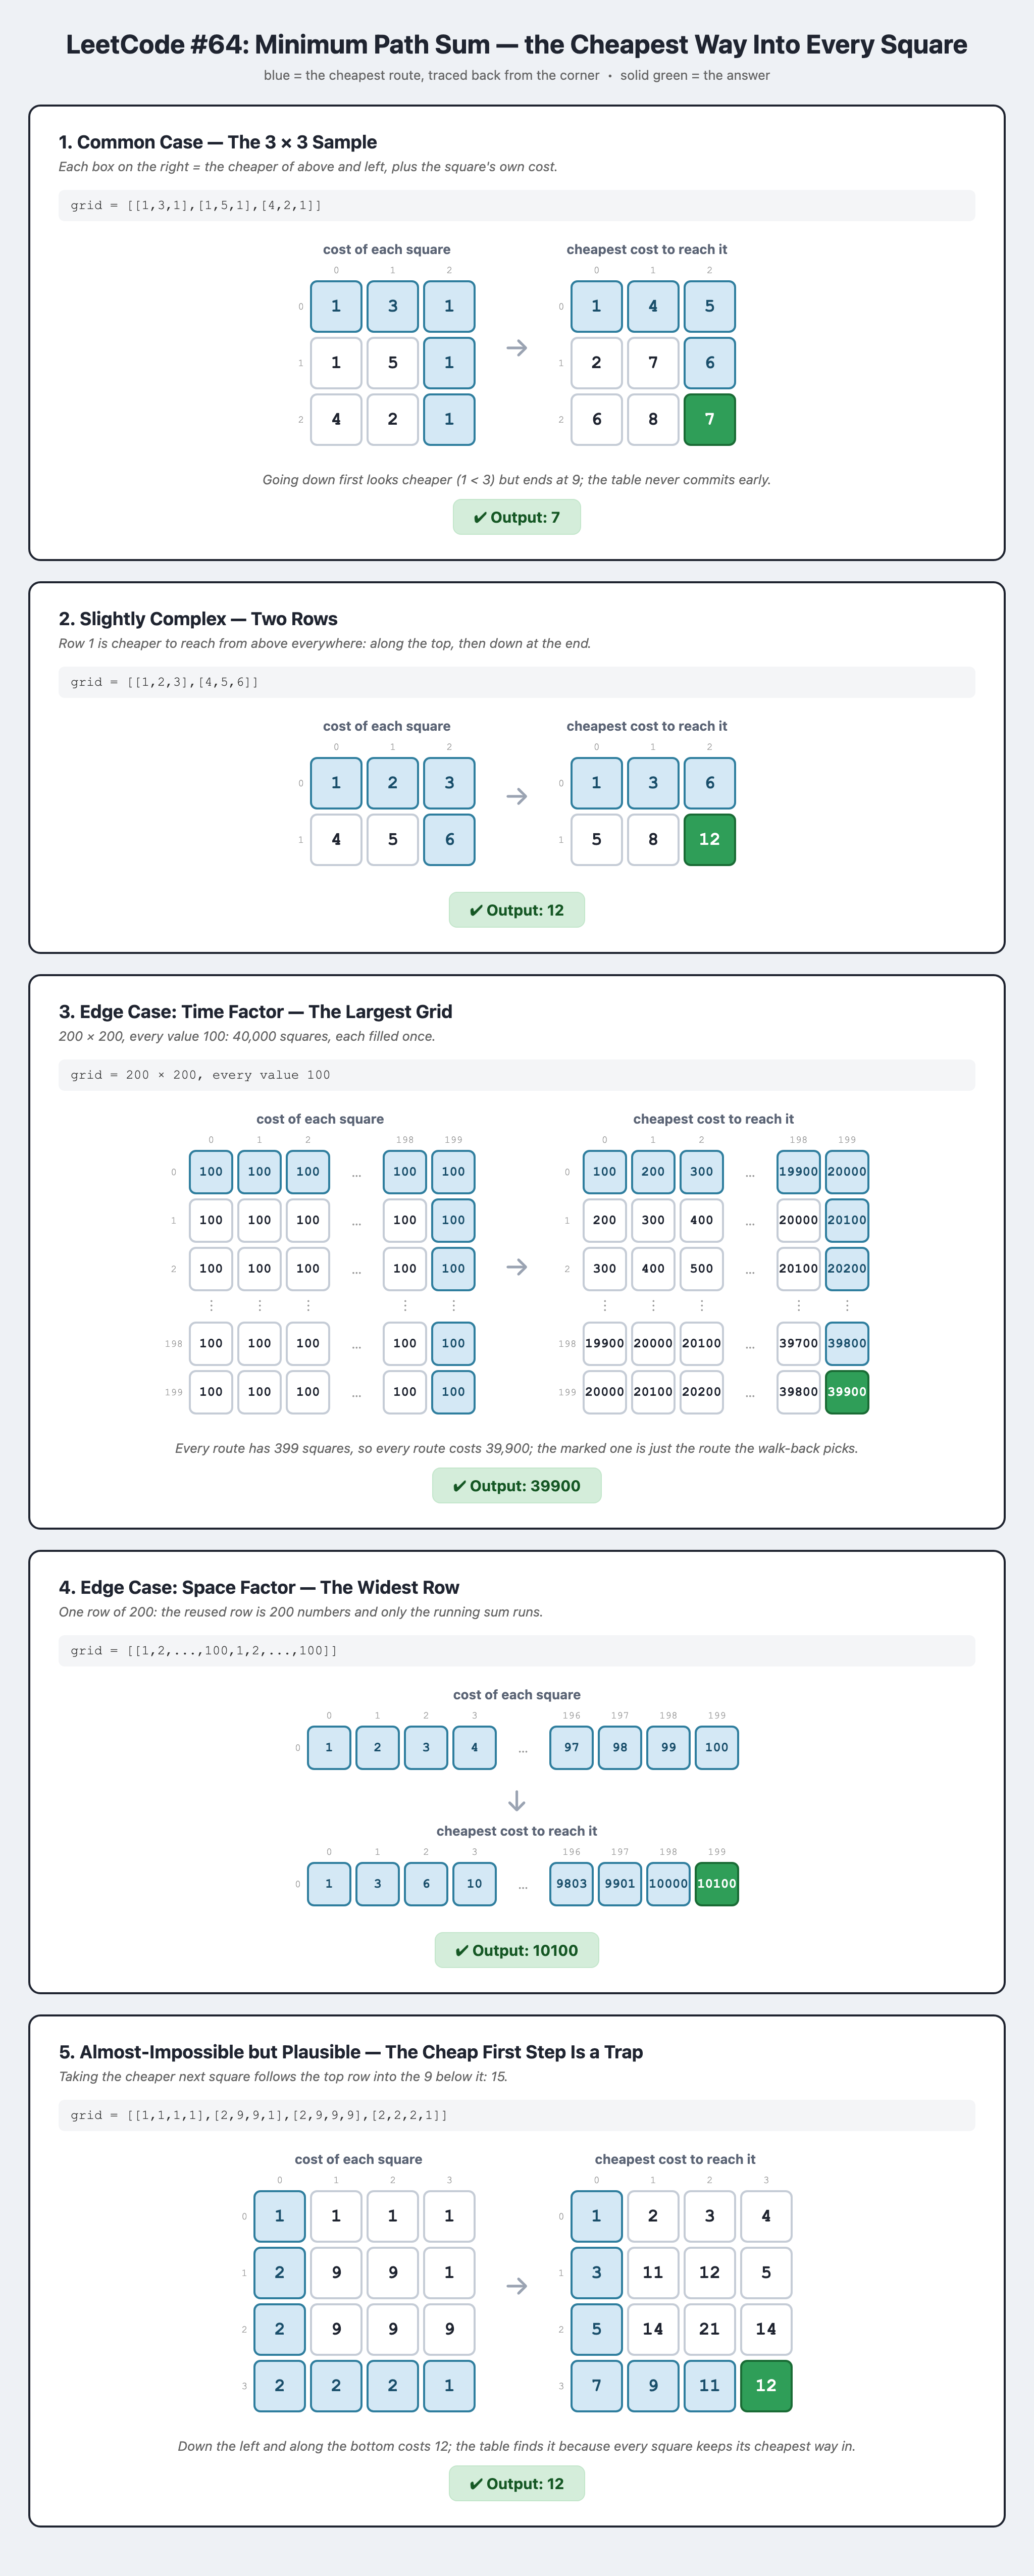

## Watch It Run

*Watch (1,1): it compares 4 from above with 2 from the left, keeps the 2, and that habit of keeping only the cheapest way in builds the corner's 7.*

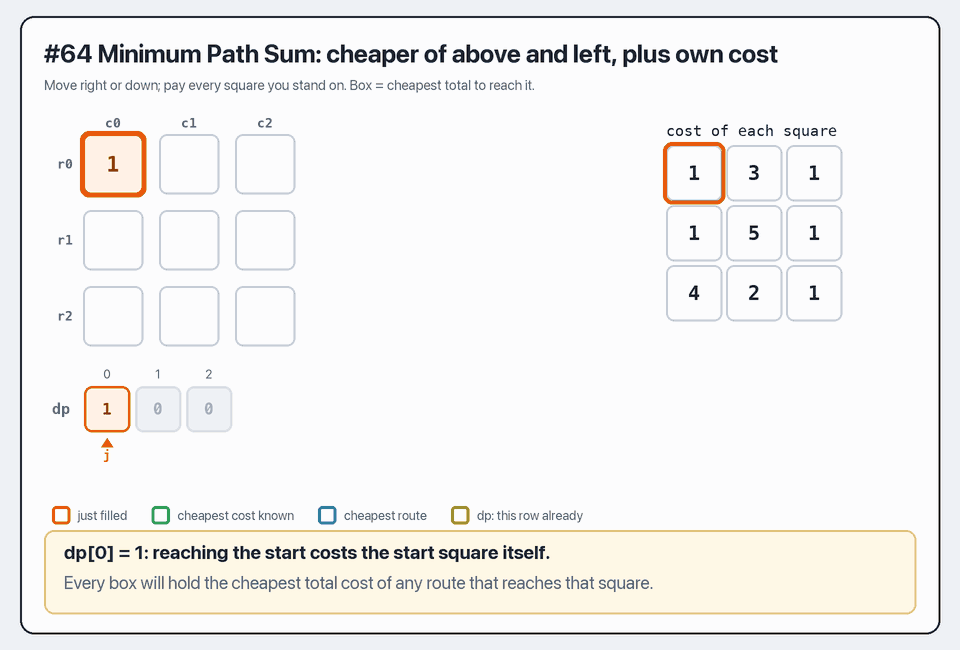

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0064.html)**